## Ćwiczenie 6 – Rozszerzenie 2: Zaawansowana detekcja krawędzi – detektor Canny'ego

### 1. Podbudowa Teoretyczna

#### Dlaczego prosta binaryzacja gradientu (Sobel) zawodzi?
Proste progowanie gradientu (Sobel, Prewitt) cierpi na dwa główne problemy:
1. **Grube krawędzie:** Krawędzie na obrazie gradientu mają szerokość kilku pikseli.
2. **Brak ciągłości (Dziury):** Lokalne spadki kontrastu powodują przerwanie ciągłości konturu.

#### Algorytm Johna F. Canny'ego (1986)
Detektor Canny'ego jest uznawany za optymalny detektor krawędzi. Składa się z **4 precyzyjnych kroków**:

1. **Filtracja Gaussem:** Redukcja szumu wysokoczęstotliwościowego.
2. **Obliczenie gradientu i kierunku:** Wyznaczenie wartości $G = \sqrt{G_x^2 + G_y^2}$ oraz kąta orientacji $\theta = \arctan(G_y / G_x)$.
3. **Tłumienie niemaksymalne (Non-Maximum Suppression - NMS):** Cienkienie krawędzi. Piksel jest zachowywany tylko wtedy, gdy jego wartość jest lokalnym maksimum w kierunku gradientu $\theta$. Wynikiem są krawędzie o szerokości **1 piksela**.
4. **Progowanie z histerezą (Hysteresis Thresholding):**
   Używa dwóch progów: **$T_{\text{high}}$** oraz **$T_{\text{low}}$**:
   * Piksele o gradienicie $> T_{\text{high}}$ są uznawane za **Pewne Krawędzie**.
   * Piksele o gradiencie $< T_{\text{low}}$ są **Odrzucane**.
   * Piksele pomiędzy $T_{\text{low}}$ a $T_{\text{high}}$ są zachowywane **Tylko wtedy, gdy łączą się bezpośrednio z Pewną Krawędzią**.

Dzięki histerezie algorytm Canny'ego potrafi „łatać” przerwy w konturach narządów!

C:\ProgramData\anaconda3\Lib\site-packages\paramiko\pkey.py:82: CryptographyDeprecationWarning: TripleDES has been moved to cryptography.hazmat.decrepit.ciphers.algorithms.TripleDES and will be removed from this module in 48.0.0.
  "cipher": algorithms.TripleDES,
C:\ProgramData\anaconda3\Lib\site-packages\paramiko\transport.py:219: CryptographyDeprecationWarning: Blowfish has been moved to cryptography.hazmat.decrepit.ciphers.algorithms.Blowfish and will be removed from this module in 45.0.0.
  "class": algorithms.Blowfish,
C:\ProgramData\anaconda3\Lib\site-packages\paramiko\transport.py:243: CryptographyDeprecationWarning: TripleDES has been moved to cryptography.hazmat.decrepit.ciphers.algorithms.TripleDES and will be removed from this module in 48.0.0.
  "class": algorithms.TripleDES,


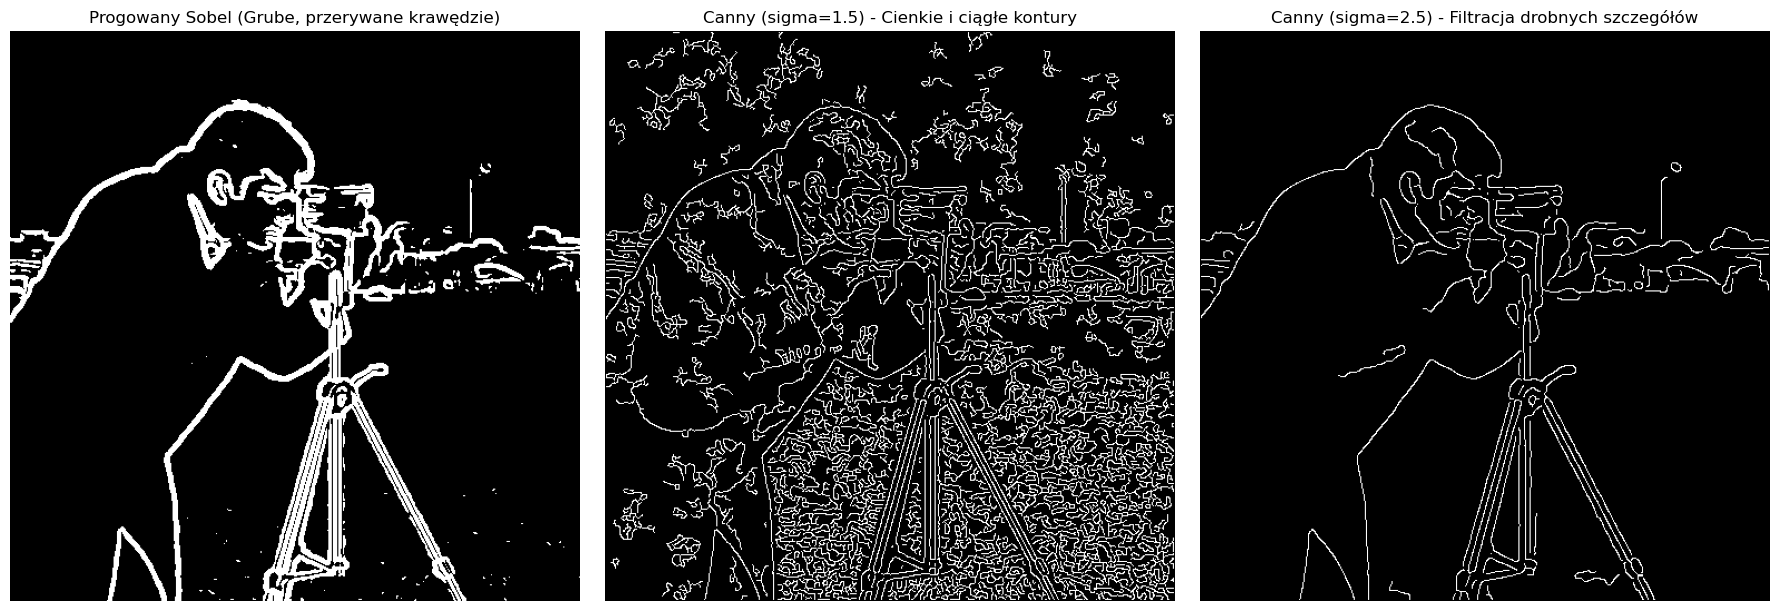

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data, feature, filters, util

# Wczytanie obrazu i dodanie szumu
image = data.camera() / 255.0
noisy_image = util.random_noise(image, mode='gaussian', var=0.005)

# 1. Tradycyjny Sobel + Binaryzacja
sobel_edges = filters.sobel(filters.gaussian(noisy_image, sigma=1.5)) > 0.05

# 2. Detektor Canny'ego
canny_edges_1 = feature.canny(noisy_image, sigma=1.5, low_threshold=0.05, high_threshold=0.15)
canny_edges_2 = feature.canny(noisy_image, sigma=2.5, low_threshold=0.05, high_threshold=0.15)

# Vizualizacja porównawcza
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
axes[0].imshow(sobel_edges, cmap='gray')
axes[0].set_title('Progowany Sobel (Grube, przerywane krawędzie)')

axes[1].imshow(canny_edges_1, cmap='gray')
axes[1].set_title('Canny (sigma=1.5) - Cienkie i ciągłe kontury')

axes[2].imshow(canny_edges_2, cmap='gray')
axes[2].set_title('Canny (sigma=2.5) - Filtracja drobnych szczegółów')

for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

### Pytanie analityczne dla studenta:
*Zwróć uwagę na grubości krawędzi w metodzie Sobela oraz w detektorze Canny'ego. Dlaczego krawędzie o grubości 1 piksela są tak pożądane przy dalszej automatycznej pomiarowości (np. wyliczaniu pola powierzchni narządu)?*